# 人工データによる広告効果のベイズ推定

2媒体の基本的なMMMを使い，推定と未使用期間での予測を確認する．全セルは単一の設定で実行した結果を含む．

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from mmm_demo.analysis import (
    Settings, generate_data, fit, draw_parameters, predict, parameter_summary, evaluate,
)
from mmm_demo.plots import save_figures
settings = Settings()
print(settings)

Settings(seed=2026, weeks=156, train_weeks=124, grid_points=51, posterior_draws=4000, alpha=(0.4, 0.65), beta=(18.0, 26.0), saturation=(60.0, 90.0), intercept=30.0, noise_sd=2.5)


## 1．データと分割

156週のうち先頭124週で推定し，残り32週で評価する．true_meanは評価用の真値であり，推定には渡さない．

In [2]:
data = generate_data(settings)
display(data.head())
print(data.groupby('split', sort=False).size().to_string())

,week,spend_a,spend_b,outcome,true_mean,split
0,1,22.135728,49.062118,41.701586,44.024020,train
1,2,13.473856,92.614660,49.772317,49.972930,train
2,3,42.154047,36.603611,53.500746,53.002366,train
3,4,27.487212,50.799294,51.386412,53.218983,train
4,5,28.040529,37.959626,50.543735,52.817033,train


split
train    124
test      32


## 2．事後分布の計算

alphaは一様事前分布の格子近似，切片とbetaは独立なNormal(0, 50²)とする．半飽和点とノイズ標準偏差は既知と仮定する．MCMCは使わず，係数の条件付き事後分布を解析的に計算する．

In [3]:
spend = data[['spend_a', 'spend_b']].to_numpy()
n_train = settings.train_weeks
posterior = fit(spend[:n_train], data.outcome.to_numpy()[:n_train], settings)
draws = draw_parameters(posterior, settings)
parameters = parameter_summary(draws, settings)
display(parameters.round(3))
print('Posterior mass:', round(float(posterior['weights'].sum()), 8))

,parameter,truth,posterior_mean,credible_low,credible_high
0,alpha_a,0.40,0.496,0.343,0.618
1,alpha_b,0.65,0.583,0.363,0.735
2,intercept,30.00,29.481,24.881,34.006
3,beta_a,18.00,26.413,19.801,33.154
4,beta_b,26.00,19.062,11.523,27.545


Posterior mass: 1.0


## 3．検証期間の予測

検証期間の成果は推定に使わない．支出は既知として扱う．予測には，学習期間から引き継いだ持続効果を含める．予測区間には観測ノイズも含める．

In [4]:
predictions = predict(spend, posterior, draws, settings)
metrics = evaluate(data, predictions, settings)
display(pd.Series(metrics, name='value').to_frame().round(3))

,value
train_weeks,124.000
test_weeks,32.000
test_rmse,2.842
test_mae,2.249
train_mean_baseline_rmse,3.853
test_predictive_90_coverage,0.781
test_predictive_90_mean_width,8.381


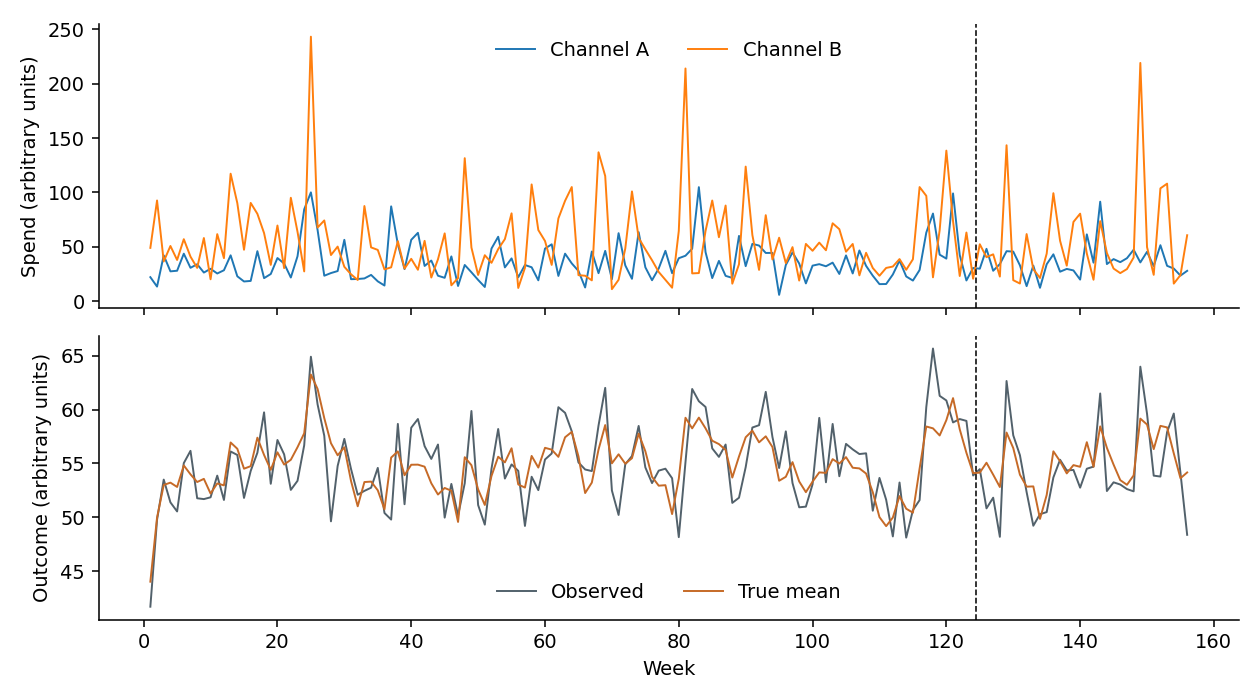

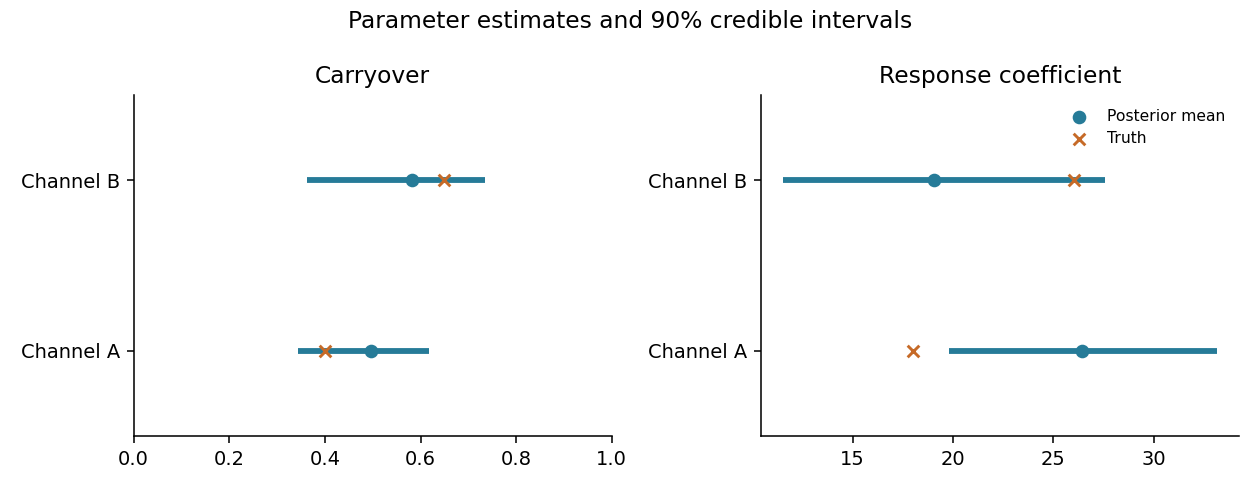

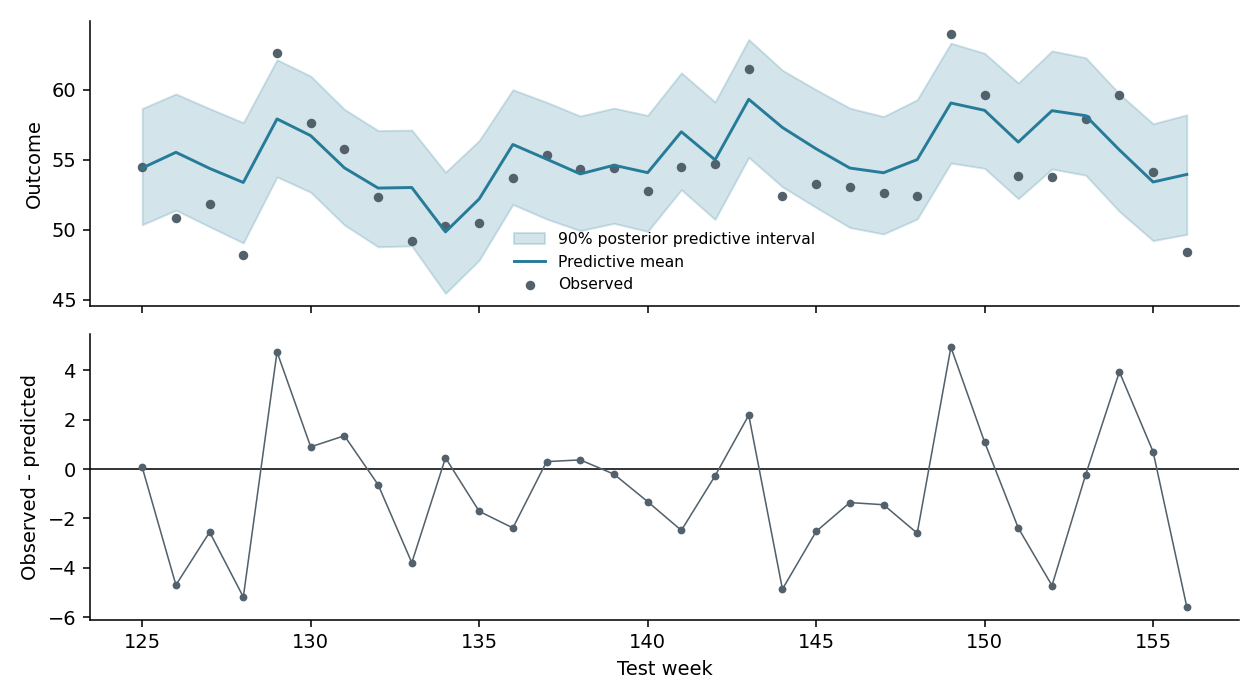

In [5]:
save_figures(data, predictions, parameters, ROOT / 'reports' / 'figures')
display(Image(filename=str(ROOT / 'reports' / 'figures' / '01_data.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / '02_parameters.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / '03_prediction.png')))

## 解釈の範囲

この分析は，生成モデルと推定モデルの形を揃えた人工データ1条件の例である．真値と推定幅の比較，予測と残差の確認を示すものであり，実市場の因果効果を検証してはいない．半飽和点とノイズ標準偏差は既知，係数は負値も許す．季節性・交絡・モデル誤指定は扱わない．32週の被覆割合だけでは，予測区間の校正を十分に評価できない．モデルの定義と背景文献はREADMEに記載した．